In [40]:
from abacusnbody.data import read_asdf
import numpy as np
import matplotlib.pyplot as plt
from abacusnbody.analysis.power_spectrum import calc_power
import os
from astropy.table import vstack

In [45]:
#read in files
filelist = []
for root, dirs, files in os.walk('earlydata/z0.800'):
    for file in files:
        if "asdf" in file:
            filelist.append(root+"/"+file)

In [46]:
tables = [read_asdf(file) for file in filelist]
z0_8tab = vstack(tables)

In [49]:
particlescut = z0_8tab[(z0_8tab['pos'][:,2] < -500)&(z0_8tab['pos'][:,2] > -550)]

Text(0, 0.5, 'Y Position (Mpc/h)')

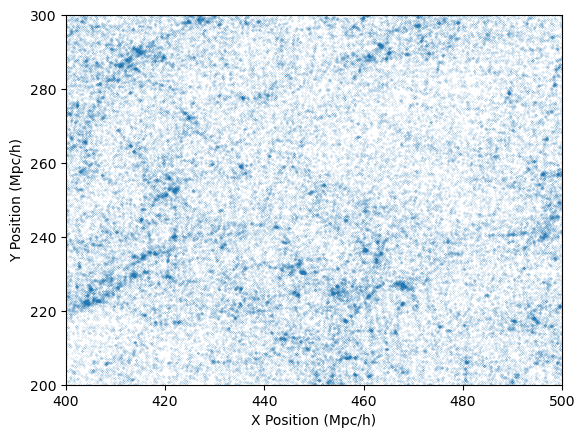

In [50]:
particlescut['x'] = particlescut['pos'][:,0]
particlescut['y'] = particlescut['pos'][:,1]
plt.scatter(particlescut['x'],particlescut['y'],s=0.01)
plt.xlim(400,500)
plt.ylim(200,300)
plt.xlabel("X Position (Mpc/h)")
plt.ylabel("Y Position (Mpc/h)")

In [51]:
print(np.min(z0_8tab['pos'][:,0])-np.max(z0_8tab['pos'][:,0]))
print(np.min(z0_8tab['pos'][:,1])-np.max(z0_8tab['pos'][:,1]))
print(np.min(z0_8tab['pos'][:,2])-np.max(z0_8tab['pos'][:,2]))

-1200.0
-1200.0
-1200.0


In [55]:
pos = z0_8tab['pos']
Lbox = 1200
nmesh = 1200

In [57]:
power = calc_power(
    pos,
    Lbox,
    nmesh = nmesh)

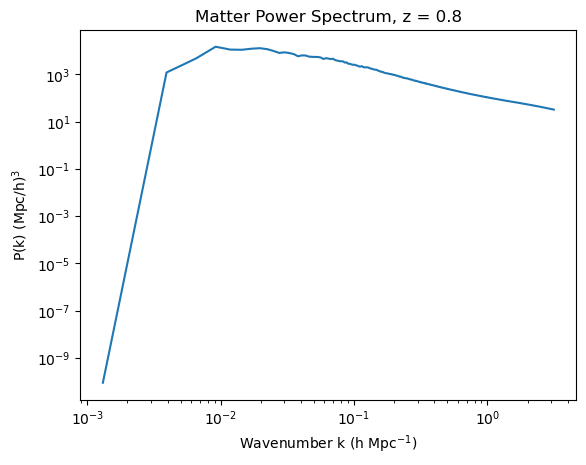

In [63]:
plt.plot(power['k_mid'],power['power'])
plt.xlabel(r"Wavenumber k (h Mpc$^{-1}$)")
plt.ylabel(r"P(k) (Mpc/h)$^3$")
plt.xscale('log')
plt.title("Matter Power Spectrum, z = 0.8")
plt.yscale('log')